# Task 3 · Track Fast Motion (30 marks)

Make Lucas-Kanade follow large motion: iterate it, track many points reliably,
and start it from SIFT matches when the motion is too large. The flow $(u, v)$
moves a point from image0 to image1: `[x + u, y + v]`.

**How this notebook works**

* Write your code only in the cells whose first line starts with `# YOUR CODE`.
  Only those cells are graded, and they are read from the **saved** notebook.
  Add your own cells anywhere for experiments or notes: they are never graded.
  A helper function you want graded with your code goes in a `# YOUR CODE` cell
  (a new cell whose first line is `# YOUR CODE` works too).
* Run the `check(...)` cell after your code: it tests your functions and prints
  PASS or FAIL for each test.
* Answer each question in the cell right below it, in one or two sentences,
  replacing *TODO*.
* Save often (Ctrl+S). Before you submit, run everything from a clean start:
  restart the kernel and run all cells, or run `python run_notebooks.py`.

In [1]:
# PROVIDED: run this cell first (save task2.ipynb before)
%matplotlib inline
import numpy as np
from provided.notebook import check, use_my_functions
from provided.sampling import bilinear_sample
from provided.sift import sift_matches, track_with_sift
from provided.task3.steps import compare_pair, error_sweep

use_my_functions(2)               # your Task 1 and 2 functions, from the saved notebooks

your functions from task1.ipynb, task2.ipynb (the saved files): spatial_gradients, temporal_difference, structure_tensor, feature_score, select_features, lucas_kanade_update, one_step_flow


## 3.1 Iterative Lucas-Kanade (9 marks)

Start from $(u,v)=(0,0)$ or from a given initial guess, warp the second image
with bilinear sampling, and repeat the Task 2 update until the increment is
small or a maximum iteration count is reached. The provided cell adds your
iterative curve to the error sweep of Task 2.3.

In [4]:
# YOUR CODE: Task 3.1

def track_point(image0, image1, point, window_radius=7, max_iterations=10, tolerance=1e-3,
                grad0=None, initial=None):
    """Track one point from image0 to image1 by repeating the Task 2 update (Task 3.1).

    initial : optional starting [u, v] instead of (0, 0), e.g. a SIFT guess.
    Returns (new_point, ok): new_point = np.array([x + u, y + v]); ok is False if
    the window leaves either image or the update cannot be solved.

    How to write it:
      1. Set up the window as in one_step_flow and sample, once, the image0 window
         (the template) and its Ix and Iy windows.
      2. Start from (u, v) = initial, or (0, 0).
      3. Up to max_iterations times:
           * sample image1 on the shifted window (xs + u, ys + v); if any sample
             is outside, return (np.array([x + u, y + v]), False);
           * step = lucas_kanade_update(Ix window, Iy window, image1 window - template);
             if it is None, return failure the same way;
           * add the step to (u, v); stop once np.hypot(*step) < tolerance.
      4. Return (np.array([x + u, y + v]), True).
    """
    
    
    x, y = point
    r = window_radius
    H, W = image0.shape
    
    # 1. Set up the local grid for the window
    dx_grid, dy_grid = np.meshgrid(np.arange(-r, r + 1), np.arange(-r, r + 1))
    xs = x + dx_grid
    ys = y + dy_grid
    
    # Ensure gradients are available
    if grad0 is None:
        # Assuming you have a spatial_gradients function from Task 1
        ix, iy = spatial_gradients(image0) 
    else:
        ix, iy = grad0
        
    template,_ = bilinear_sample(image0, xs, ys)
    ix_window,_ = bilinear_sample(ix, xs, ys)
    iy_window,_ = bilinear_sample(iy, xs, ys)
    
    # 2. Start from initial guess or (0,0)
    if initial is not None:
        u, v = float(initial[0]), float(initial[1])
    else:
        u, v = 0.0, 0.0
        
    # 3. Iteration loop
    for i in range(max_iterations):
        # Shift the sampling coordinates by our current motion estimate
        xs_shifted = xs + u
        ys_shifted = ys + v
        
        # Check bounds: if the shifted window falls off the image, tracking fails
        if (np.min(xs_shifted) < 0 or np.max(xs_shifted) > W - 1 or
            np.min(ys_shifted) < 0 or np.max(ys_shifted) > H - 1):
            return (np.array([x + u, y + v]), False)
            
        # Sample the new image at the shifted, subpixel coordinates
        img1_window,_ = bilinear_sample(image1, xs_shifted, ys_shifted)
        
        # Compute the temporal difference (residual error)
        It_window = img1_window - template
        
        step = lucas_kanade_update(ix_window, iy_window, It_window)
        
        if step is None:
            # Tracking fails if the matrix becomes singular/unsolvable
            return (np.array([x + u, y + v]), False)
            
        du, dv = step
        
        # Update our current motion estimate
        u += du
        v += dv
        
        # Check for convergence: if the step size is tiny, we have found the minimum
        if np.hypot(du, dv) < tolerance:
            break
            
    # 4. Return the final tracked position and success flag
    return (np.array([x + u, y + v]), True)

In [5]:
check("3.1")

Task 3.1 checks
  PASS  track point recovers a subpixel shift
  PASS  iterations do not hurt
  PASS  track point fails when the window leaves the image
  PASS  track point starts from the initial guess
4 of 4 passed


True

  saved outputs/task3/error_sweep.json
  saved outputs/task3/error_sweep.png


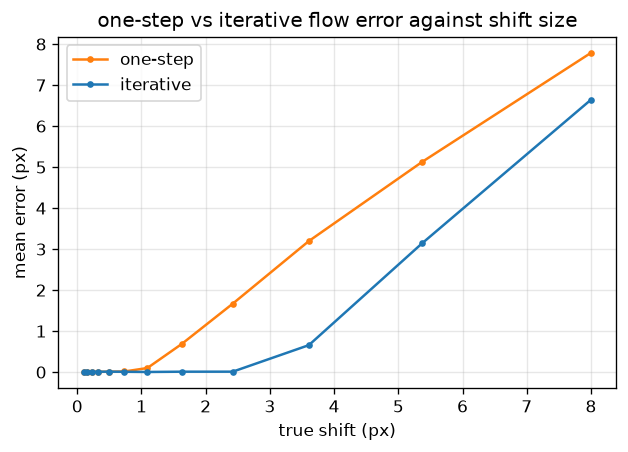

    shift  0.10 px: one-step 0.002 px, iterative 0.004 px
    shift  0.15 px: one-step 0.003 px, iterative 0.006 px
    shift  0.22 px: one-step 0.005 px, iterative 0.008 px
    shift  0.33 px: one-step 0.007 px, iterative 0.010 px
    shift  0.49 px: one-step 0.010 px, iterative 0.011 px
    shift  0.73 px: one-step 0.015 px, iterative 0.009 px
    shift  1.09 px: one-step 0.100 px, iterative 0.004 px
    shift  1.63 px: one-step 0.685 px, iterative 0.011 px
    shift  2.42 px: one-step 1.670 px, iterative 0.011 px
    shift  3.61 px: one-step 3.197 px, iterative 0.658 px
    shift  5.37 px: one-step 5.128 px, iterative 3.143 px
    shift  8.00 px: one-step 7.788 px, iterative 6.644 px


In [6]:
curves = error_sweep(select_features, spatial_gradients, one_step_flow, track_point)

**(a)** Up to what shift does the iterative tracker stay accurate?

Upto 2.5 px shift iterative tracker has almost 0px error then it starts to shoot up

## 3.2 Track many points (6 marks)

Track many points at once and mark a track as failed when its window leaves
either image or the least-squares system cannot be solved.

In [9]:
# YOUR CODE: Task 3.2

def track_points(image0, image1, points, window_radius=7, max_iterations=10, tolerance=1e-3,
                 initial=None):
    """Track many points with track_point (Task 3.2).

    initial : optional (N, 2) array of starting [u, v], one per point.
    Returns (tracked, valid): an (N, 2) array of new positions and an (N,) bool
    array, False for failed tracks.

    How to write it: compute grad0 = spatial_gradients(image0) once, then loop over
    the points, passing grad0 and initial[k] (when given) to track_point. Fill
    np.zeros((N, 2)) and np.zeros(N, dtype=bool) with the results.
    """
    N = points.shape[0]
    tracked = np.zeros((N, 2))
    valid = np.zeros(N, dtype=bool)
    
    # 1. Precompute the global gradient field once for the entire image
    # Note: Replace 'spatial_gradients' with your actual Task 1.1 function name
    grad0 = spatial_gradients(image0)
    
    # 2. Iterate through each feature point
    for k in range(N):
        point = points[k]
        init_guess = initial[k] if initial is not None else None
        
        # 3. Track the individual point using the precomputed global gradient
        new_pt, ok = track_point(
            image0, image1, point, 
            window_radius=window_radius, 
            max_iterations=max_iterations, 
            tolerance=tolerance,
            grad0=grad0, 
            initial=init_guess
        )
        
        # 4. Store the results
        tracked[k] = new_pt
        valid[k] = ok
        
    return tracked, valid

In [10]:
check("3.2")

Task 3.2 checks
  PASS  track points accepts one initial guess per point
  PASS  track points returns positions and validity
2 of 2 passed


True

**(a)** Can a track that is marked valid still be wrong? Give an example from your results.

A track marked valid can still be incorrect because passing validity checks does not guarantee that the tracker has matched the same physical feature across frames. For example, in the frame pair 300 → 301, some orange arrows near the upper-left region point in inconsistent directions.

## 3.3 Use SIFT to handle large motion (7 marks)

The provided `track_with_sift` (in `provided/sift.py`) runs your `track_points`
from $(0, 0)$ and from a SIFT starting guess and keeps the better fit:

```python
tracked, valid = track_with_sift(track_points, image0, image1, points,
                                 sift_matches(image0, image1))
```

In [11]:
check("3.3")

Task 3.3 checks
  PASS  track with sift recovers motion too large for zero start
1 of 1 passed


True

**(a)** Why do iterative and SIFT-guided tracking give almost the same result on 375 to 376, but very different results on 300 to 301? Use the numbers of Task 3.4.

For frames 375 → 376, the motion is small, so iterative Lucas–Kanade converges close to the correct displacement even without SIFT initialization. Therefore, both methods produce nearly identical results.

For frames 300 → 301, the motion is larger, making the initial estimate less reliable. Iterative Lucas–Kanade may converge to an incorrect local solution, while SIFT provides a better initial displacement, leading to significantly different results.

## 3.4 Compare the three trackers (8 marks)

Compare one-step, iterative and SIFT-guided tracking on the two pairs of
Task 2.3 and on a third pair near touchdown (409 to 410). The provided cells
print the numbers and overlay all three trackers in one figure per pair.

  small_motion (375 to 376)    one-step: mean 1.06 px, failed-track rate 0.00
  saved outputs/task3/small_motion_one_step.png
  small_motion (375 to 376)   iterative: mean 1.29 px, failed-track rate 0.02
  saved outputs/task3/small_motion_iterative.png
  small_motion (375 to 376) sift-guided: mean 1.29 px, failed-track rate 0.02
  saved outputs/task3/small_motion_sift_guided.png
  saved outputs/task3/small_motion_statistics.json
  saved outputs/task3/small_motion_compare.png


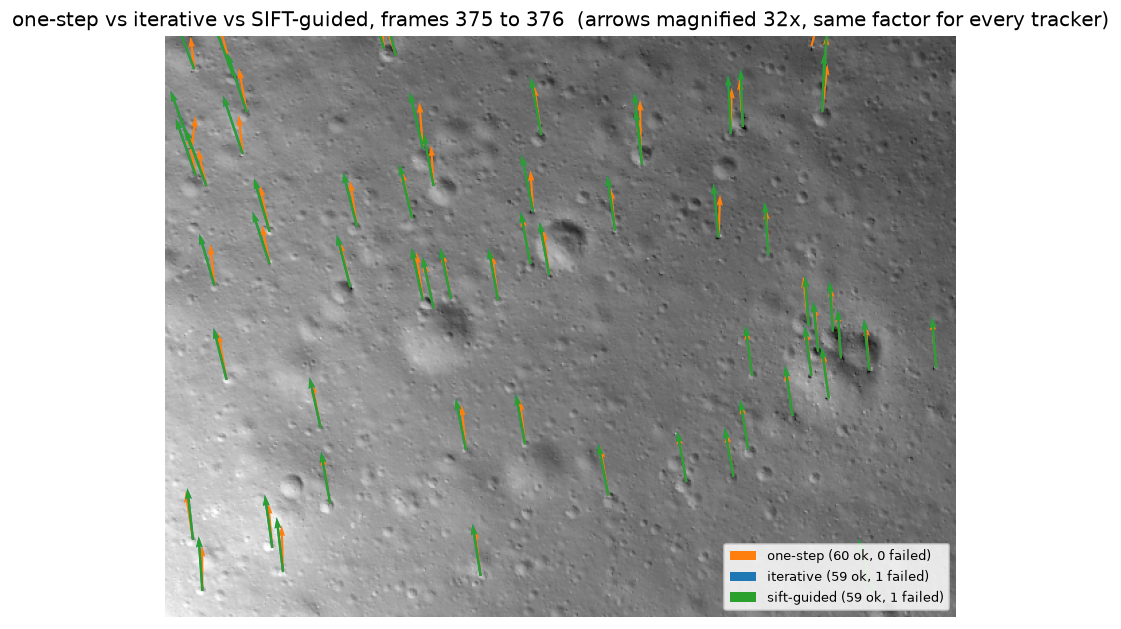

In [12]:
small = compare_pair("small_motion", select_features, track_points)

  large_motion (300 to 301)    one-step: mean 0.29 px, failed-track rate 0.05
  saved outputs/task3/large_motion_one_step.png
  large_motion (300 to 301)   iterative: mean 2.38 px, failed-track rate 0.07
  saved outputs/task3/large_motion_iterative.png
  large_motion (300 to 301) sift-guided: mean 9.98 px, failed-track rate 0.12
  saved outputs/task3/large_motion_sift_guided.png
  saved outputs/task3/large_motion_statistics.json
  saved outputs/task3/large_motion_compare.png


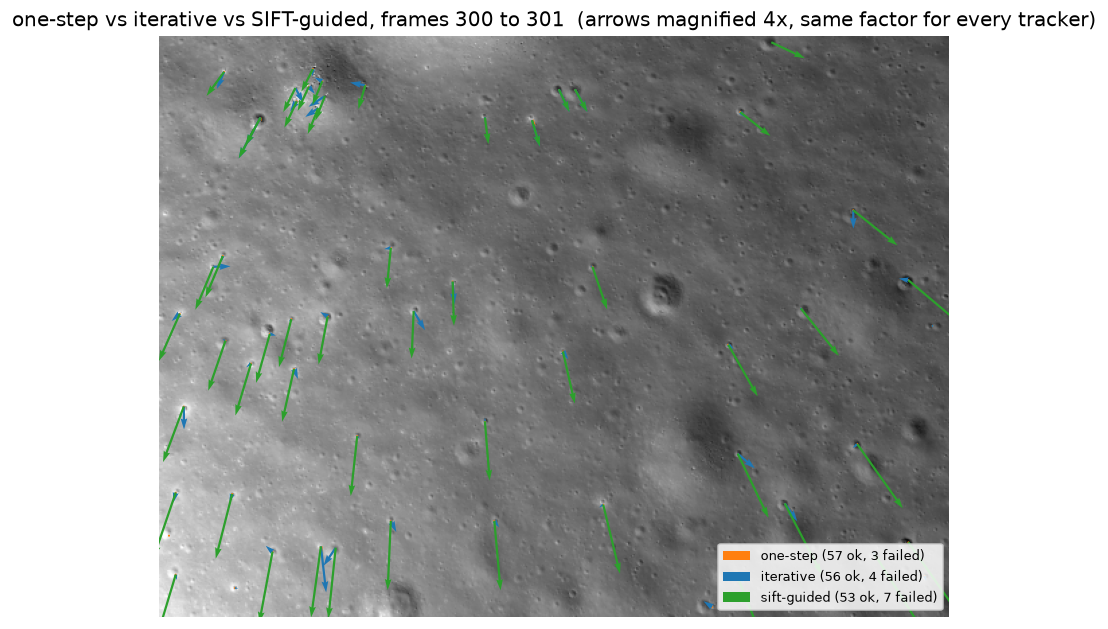

In [13]:
large = compare_pair("large_motion", select_features, track_points)

  touchdown (409 to 410)    one-step: mean 0.30 px, failed-track rate 0.08
  saved outputs/task3/touchdown_one_step.png
  touchdown (409 to 410)   iterative: mean 2.52 px, failed-track rate 0.13
  saved outputs/task3/touchdown_iterative.png
  touchdown (409 to 410) sift-guided: mean 32.74 px, failed-track rate 0.60
  saved outputs/task3/touchdown_sift_guided.png
  saved outputs/task3/touchdown_statistics.json
  saved outputs/task3/touchdown_compare.png


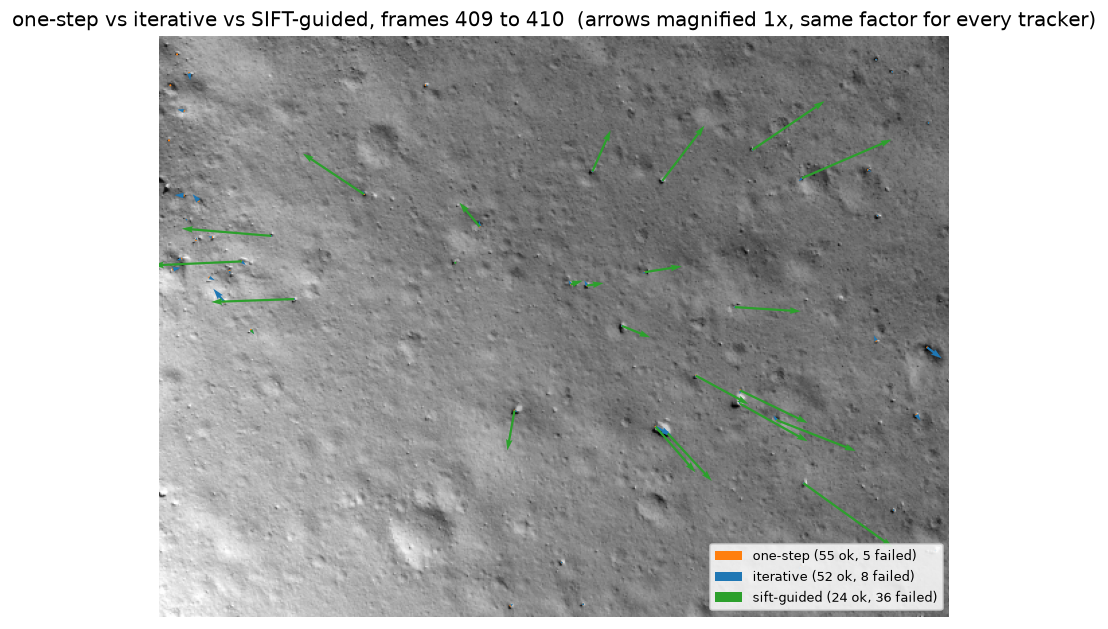

In [14]:
touchdown = compare_pair("touchdown", select_features, track_points)

**Table.** Fill in the mean displacement (px) and the failed-track rate (0 to 1) printed above.



| Pair      | One-step (mean px, failure rate) | Iterative (mean px, failure rate) | SIFT-guided (mean px, failure rate) |
| --------- | -------------------------------- | --------------------------------- | ----------------------------------- |
| 375 → 376 | 1.06 px, 0.00                    | 1.29 px, 0.02                     | 1.29 px, 0.02                       |
| 300 → 301 | 0.29 px, 0.05                    | 2.38 px, 0.07                     | 9.98 px, 0.12                       |
| 409 → 410 | 0.30 px, 0.08                    | 2.52 px, 0.13                     | 32.74 px, 0.60                      |


**(a)** Which tracker is right on each pair?

375 → 376: Iterative and SIFT-guided tracking agree closely at 1.29 pixels, suggesting consistent estimates. One-step tracking is reasonably close.



300 → 301: SIFT-guided tracking is better suited to the large motion because it provides a stronger initial displacement estimate. One-step flow substantially underestimates the motion.



409 → 410: No tracker can be declared correct from these statistics alone. SIFT-guided tracking estimates 32.74 pixels but has a high failure rate of 0.60. The overlays are needed to judge accuracy.

**(b)** Why does SIFT-guided tracking lose many points at 409 to 410?

Near touchdown, large apparent motion and changes in feature scale can make reliable SIFT descriptor matching difficult. Features may also leave the image or become difficult to distinguish. Consequently, SIFT-guided tracking fails on 60% of the tracks, making its remaining displacement estimates less reliable.